In [1]:
import threading

# --- Tanpa Lock ---
saldo_tanpa_lock = 1000000

def transaksi_tanpa_lock():
    global saldo_tanpa_lock
    for _ in range(10000):
        saldo_tanpa_lock -= 1
        saldo_tanpa_lock += 1

threads = []
for _ in range(10):
    t = threading.Thread(target=transaksi_tanpa_lock)
    threads.append(t)
    t.start()

for t in threads:
    t.join()

print(f"Saldo Akhir (Tanpa Lock) : {saldo_tanpa_lock}")


# --- Menggunakan threading.Lock() ---
saldo_dengan_lock = 1000000
lock = threading.Lock()

def transaksi_dengan_lock():
    global saldo_dengan_lock
    for _ in range(10000):
        with lock:
            saldo_dengan_lock -= 1
            saldo_dengan_lock += 1

threads = []
for _ in range(10):
    t = threading.Thread(target=transaksi_dengan_lock)
    threads.append(t)
    t.start()

for t in threads:
    t.join()

print(f"Saldo Akhir (Dengan Lock): {saldo_dengan_lock}")

Saldo Akhir (Tanpa Lock) : 1000000
Saldo Akhir (Dengan Lock): 1000000


In [2]:
import queue
import threading
import time

q = queue.Queue()
NUM_CONSUMERS = 3

def producer():
    for i in range(10):
        item = f"Data-{i}"
        q.put(item)
        print(f"[Producer] Menghasilkan {item}")
        time.sleep(0.1)
    
    # Kirim sinyal None sebanyak jumlah consumer agar semua consumer berhenti dengan baik
    for _ in range(NUM_CONSUMERS):
        q.put(None)
    print("[Producer] Selesai mengirim seluruh data dan sinyal penghentian.")

def consumer(consumer_id):
    while True:
        item = q.get()
        if item is None:
            print(f"[Consumer {consumer_id}] Menerima sinyal berhenti (None). Keluar.")
            q.task_done()
            break
        print(f"[Consumer {consumer_id}] Memproses {item}")
        time.sleep(0.2)
        q.task_done()

# Menjalankan 1 Producer Thread
t_prod = threading.Thread(target=producer)
t_prod.start()

# Menjalankan 3 Consumer Threads
t_cons_list = []
for i in range(1, NUM_CONSUMERS + 1):
    t = threading.Thread(target=consumer, args=(i,))
    t_cons_list.append(t)
    t.start()

t_prod.join()
for t in t_cons_list:
    t.join()

q.join()
print("Semua proses Producer-Consumer selesai.")

[Producer] Menghasilkan Data-0
[Consumer 1] Memproses Data-0
[Producer] Menghasilkan Data-1
[Consumer 2] Memproses Data-1
[Producer] Menghasilkan Data-2
[Consumer 3] Memproses Data-2
[Producer] Menghasilkan Data-3[Consumer 1] Memproses Data-3

[Producer] Menghasilkan Data-4
[Consumer 2] Memproses Data-4
[Producer] Menghasilkan Data-5
[Consumer 3] Memproses Data-5
[Producer] Menghasilkan Data-6[Consumer 1] Memproses Data-6

[Producer] Menghasilkan Data-7
[Consumer 2] Memproses Data-7
[Producer] Menghasilkan Data-8
[Consumer 3] Memproses Data-8
[Producer] Menghasilkan Data-9[Consumer 1] Memproses Data-9

[Producer] Selesai mengirim seluruh data dan sinyal penghentian.
[Consumer 2] Menerima sinyal berhenti (None). Keluar.
[Consumer 3] Menerima sinyal berhenti (None). Keluar.
[Consumer 1] Menerima sinyal berhenti (None). Keluar.
Semua proses Producer-Consumer selesai.


max_workers =  2 | Waktu Eksekusi: 2.5429 detik
max_workers =  4 | Waktu Eksekusi: 1.3139 detik
max_workers =  8 | Waktu Eksekusi: 0.7101 detik
max_workers = 16 | Waktu Eksekusi: 0.4099 detik


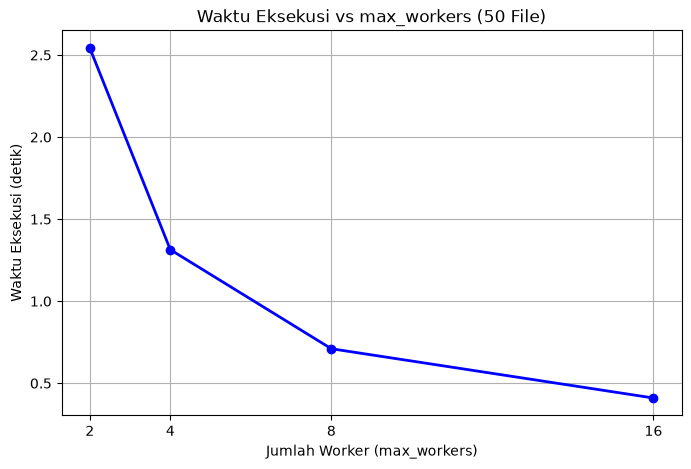

In [3]:
import concurrent.futures
import time
import matplotlib.pyplot as plt

# Simulasi pekerjaan I/O bound (misal: mengunduh/membaca 50 file)
NUM_FILES = 50

def process_file(file_id):
    time.sleep(0.1)  # Simulasi latensi I/O
    return f"File {file_id} selesai"

worker_counts = [2, 4, 8, 16]
execution_times = []

for workers in worker_counts:
    start_time = time.time()
    with concurrent.futures.ThreadPoolExecutor(max_workers=workers) as executor:
        results = list(executor.map(process_file, range(NUM_FILES)))
    end_time = time.time()
    
    duration = end_time - start_time
    execution_times.append(duration)
    print(f"max_workers = {workers:2d} | Waktu Eksekusi: {duration:.4f} detik")

# Plot Waktu Eksekusi vs max_workers
plt.figure(figsize=(8, 5))
plt.plot(worker_counts, execution_times, marker='o', linewidth=2, color='b')
plt.title("Waktu Eksekusi vs max_workers (50 File)")
plt.xlabel("Jumlah Worker (max_workers)")
plt.ylabel("Waktu Eksekusi (detik)")
plt.xticks(worker_counts)
plt.grid(True)
plt.show()

Threading Python membantu: Web scraper untuk mengambil konten dari 100 URL berbeda secara paralel. Operasi ini bersifat I/O-bound, di mana program banyak menghabiskan waktu menunggu respon jaringan, sehingga threading secara efektif memanfaatkan waktu tunggu tersebut.

Threading Python tidak membantu: Pengolahan/kompresi gambar berukuran besar (image processing) atau perkalian matriks raksasa. Operasi ini bersifat CPU-bound. Akibat Global Interpreter Lock (GIL) pada CPython, thread tidak dapat berjalan secara paralel di multi-core CPU untuk tugas komputasi berat, sehingga justru memperlambat performa karena overhead context switching. Kasus ini lebih cocok menggunakan multiprocessing.